
# Clustering: customer segments and delivery territories

An online retailer of everyday goods - household, personal care,
pet supplies - operating in **one metropolitan area** with its **own delivery
fleet** and same-day service.

Two departments, two questions, one dataset:

- **Marketing** — *"We treat every customer the same. Are there natural
  groups we should address differently?"*
- **Operations** — *"We run four micro-hubs, each with a limited capacity.
  Who should each hub serve?"* - *"We can open four micro-hubs, each with a limited capacity. Which hubs do we open? Who should each hub serve?"*

Both are clustering problems. They are **not the same kind** of clustering
problem, and the gap between them is the point of this lab.

| variable | meaning | used in |
|---|---|---|
| `x`, `y` | home location, km on a city grid | Part 2 |
| `recency` | days since last order | Part 1 |
| `frequency` | orders in the last month | **both** |
| `monetary` | average basket value (EUR) | Part 1 |
| `discount_rate` | share of orders with a coupon | Part 1 |

`frequency`: In Part 1 it is one behavioural feature among
four. In Part 2 it becomes $q_i$, **the demand** each hub must physically
serve. The same column plays both roles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.spatial.distance import cdist

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
GREEN, ACC = "#0E7800", "#D82303"

df = pd.read_excel('freshcart.xlsx')
COL = ['recency', 'frequency', 'monetary', 'discount_rate']
print(df.shape)
df.head()

(1260, 8)


,customer_id,x,y,recency,frequency,monetary,discount_rate,true_profile
0,C000,12.70,4.76,12.29,11.10,37.38,0.13,loyal
1,C001,6.25,16.77,55.67,1.52,28.33,0.53,dormant
2,C002,12.64,8.23,13.51,16.33,74.42,0.00,loyal
3,C003,7.60,12.86,19.23,7.00,126.01,0.14,premium
4,C004,5.07,4.02,22.11,10.37,12.36,0.41,bargain


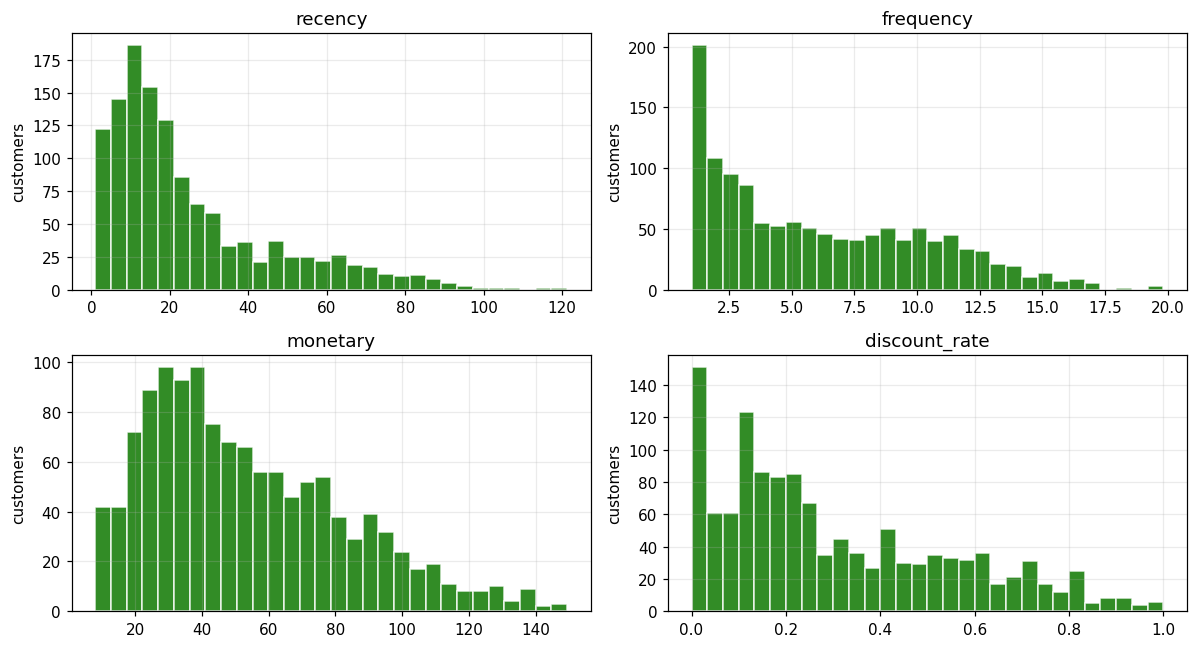

In [2]:
fig, axs = plt.subplots(2, 2, figsize=(11, 6))
for ax, c in zip(axs.ravel(), COL):
    ax.hist(df[c], bins=30, color=GREEN, edgecolor='white', alpha=.85)
    ax.set_title(c)
    ax.set_ylabel('customers')
plt.tight_layout()
plt.show()

Clustering is driven by a distance,
$d(x_i, x_l) = \sqrt{\sum_j (x_{ij} - x_{lj})^2}$.
`monetary` ranges over tens of euros, `discount_rate` over $[0, 1]$.

In [3]:
X = StandardScaler().fit_transform(df[COL])

print("std dev before scaling:", df[COL].std().round(2).to_dict())
print("std dev after  scaling:", dict(zip(COL, X.std(axis=0).round(2))))

std dev before scaling: {'recency': 21.45, 'frequency': 4.25, 'monetary': 29.69, 'discount_rate': 0.24}
std dev after  scaling: {'recency': np.float64(1.0), 'frequency': np.float64(1.0), 'monetary': np.float64(1.0), 'discount_rate': np.float64(1.0)}


Without standardisation `monetary` would decide every distance and
`discount_rate` would be invisible: we would be clustering on *units of
measurement*.

## 1.3. Hierarchical clustering

Agglomerative: start with $n$ singleton clusters, repeatedly merge the two
closest ones. The **linkage** defines "closest between clusters":

- *single*: min distance between points → chaining, elongated clusters
- *complete*: max distance → compact, similar-diameter clusters
- *average*: mean distance
- *Ward*: merge the pair that increases within-cluster variance the least

Output is a **dendrogram**: no need to fix $k$ in advance, you cut it later.

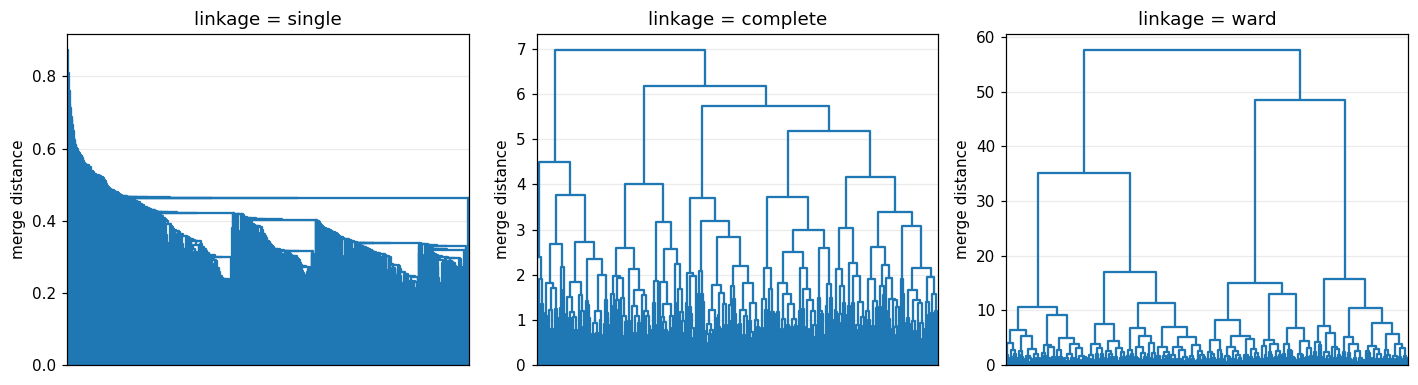

In [4]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, method in zip(axes, ["single", "complete", "ward"]):
    Z = linkage(X, method=method)
    dendrogram(Z, ax=ax, no_labels=True,
               color_threshold=0)
    ax.set_title(f"linkage = {method}")
    ax.set_ylabel("merge distance")
plt.tight_layout()
plt.show()

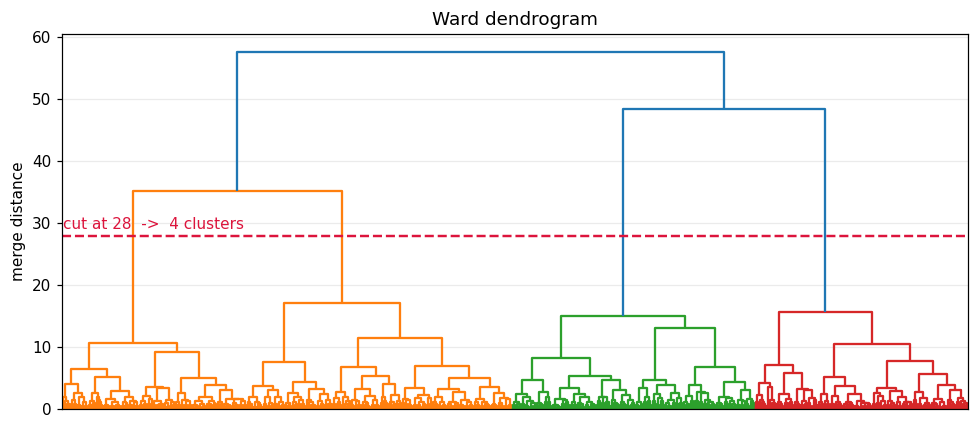

cluster sizes: [257 369 338 296]


In [5]:
Z = linkage(X, method="ward")

plt.figure(figsize=(9, 4))
dendrogram(Z, no_labels=True)
cut = 28
plt.axhline(cut, color="crimson", ls="--", lw=1.6)
plt.text(5, cut + 1, f"cut at {cut}  ->  4 clusters", color="crimson")
plt.title("Ward dendrogram")
plt.ylabel("merge distance")
plt.tight_layout()
plt.show()

labels_hier = fcluster(Z, t=4, criterion="maxclust")
print("cluster sizes:", np.bincount(labels_hier)[1:])

## 1.3 k-means, and choosing k

Fix $k$, then alternate: assign each point to the nearest centroid, then move
each centroid to the mean of its points. It is a heuristic for

$$\min_{C_1 \dots C_k} \sum_{j=1}^{k} \sum_{i \in C_j} \lVert x_i - \mu_j \rVert^2$$

Two consequences: it converges to a **local** optimum (hence `n_init`), and
minimising squared distance to a mean implies **spherical clusters of
comparable size**.

The **silhouette** of point $i$ compares its mean distance to its own cluster
($a_i$) with the mean distance to the best alternative ($b_i$):
$s_i = (b_i - a_i)/\max(a_i, b_i) \in [-1, 1]$.

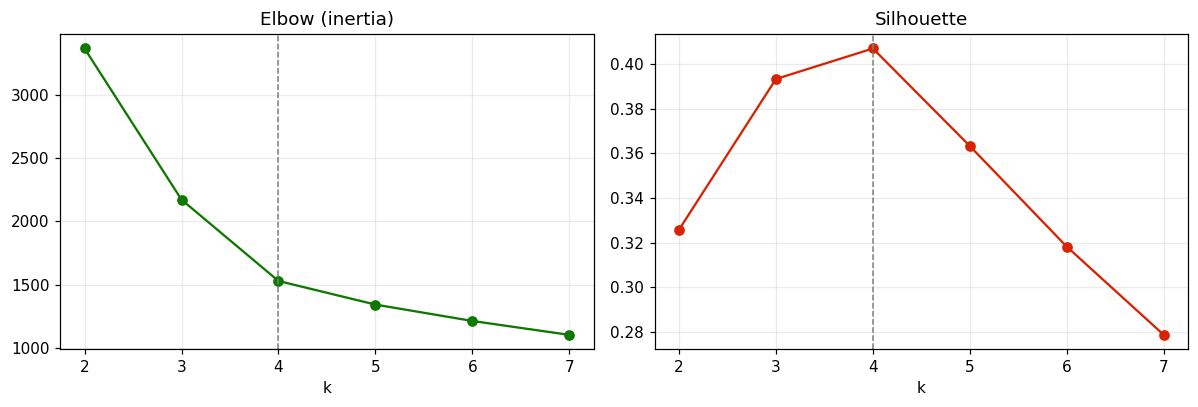

 k  inertia  silhouette
 2   3370.0       0.326
 3   2172.0       0.393
 4   1528.0       0.407
 5   1341.0       0.363
 6   1211.0       0.318
 7   1101.0       0.279


In [6]:
ks = range(2, 8)
labels, inertia, sil = {}, [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    labels[k] = km.labels_
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(list(ks), inertia, 'o-', color=GREEN)
ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(list(ks), sil, 'o-', color=ACC)
ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
for a in ax:
    a.axvline(4, ls='--', lw=1, color='grey')
plt.tight_layout()
plt.show()

print(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia),
                    'silhouette': np.round(sil, 3)}).to_string(index=False))

The honest wording is *"four defensible groups"*, not *"four natural types of customer"*.

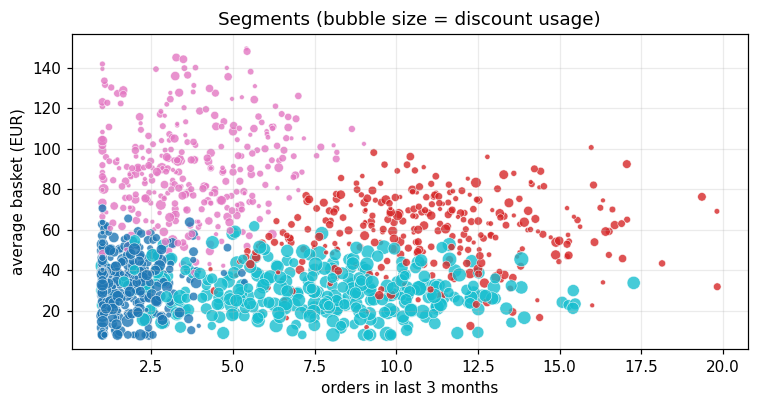

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.8))
sc = ax.scatter(df.frequency, df.monetary, c=labels[4], cmap="tab10",
                s=df.discount_rate * 90 + 10, alpha=.8, edgecolor="w", lw=.4)
ax.set_xlabel("orders in last 3 months"); ax.set_ylabel("average basket (EUR)")
ax.set_title("Segments (bubble size = discount usage)")
plt.tight_layout(); plt.show()

## 1.4 PCA — to see four dimensions on one plot

PCA here is a **lens, not a method**. We cluster in the original 4-D space
and use the 2-D projection only to look at the result.

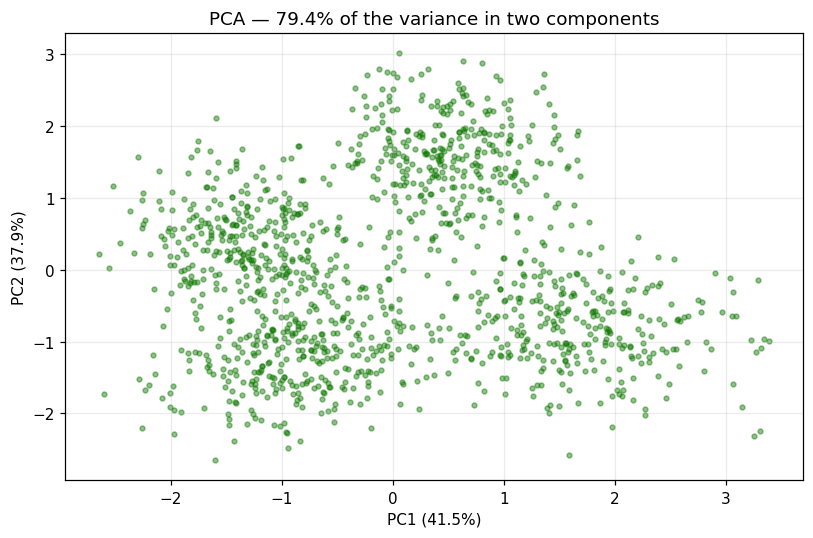

In [8]:
pca = PCA(n_components=2)
Xp = pca.fit_transform(X)
ev = pca.explained_variance_ratio_

plt.figure(figsize=(7.5, 5))
plt.scatter(Xp[:, 0], Xp[:, 1], s=10, alpha=.45, color=GREEN)
plt.xlabel(f'PC1 ({ev[0]*100:.1f}%)')
plt.ylabel(f'PC2 ({ev[1]*100:.1f}%)')
plt.title(f'PCA — {ev.sum()*100:.1f}% of the variance in two components')
plt.tight_layout()
plt.show()

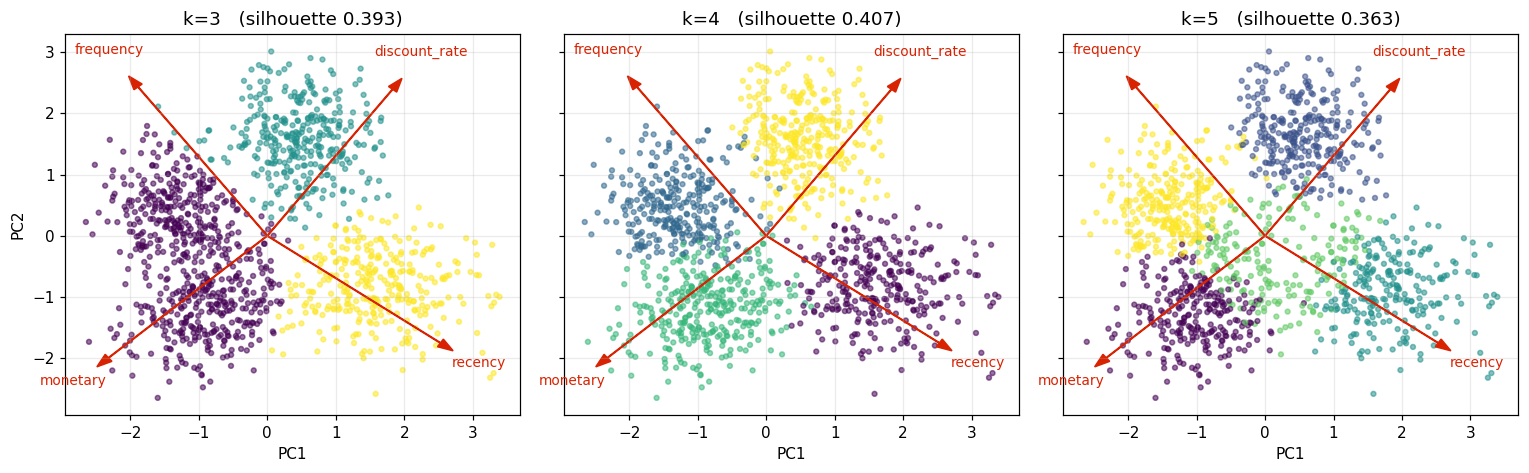

In [9]:
# biplot: clusters in PCA space, with the PCA loadings as arrows
load = pca.components_.T
scale = 0.8 * np.abs(Xp).max() / np.abs(load).max()

fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, k in zip(axs, [3, 4, 5]):
    ax.scatter(Xp[:, 0], Xp[:, 1], c=labels[k], cmap='viridis', s=10, alpha=.55)
    for i, v in enumerate(COL):
        ax.arrow(0, 0, load[i, 0]*scale, load[i, 1]*scale, color=ACC,
                 width=.01, head_width=.15, length_includes_head=True)
        ax.text(load[i, 0]*scale*1.14, load[i, 1]*scale*1.14, v,
                color=ACC, ha='center', fontsize=9)
    ax.set_title(f'k={k}   (silhouette {sil[k-2]:.3f})')
    ax.set_xlabel('PC1')
axs[0].set_ylabel('PC2')
plt.tight_layout()
plt.show()

The red arrows are the PCA **loadings**: they show which original variable
pulls in which direction, so each cluster can be read off the projection.
At $k=5$ the extra cluster splits an existing group rather than revealing a
new one.

In [10]:
print(pd.crosstab(labels_hier, labels[4],
                  rownames=["hierarchical"], colnames=["k-means"]))
print(f"\nAdjusted Rand Index (hierarchical vs k-means): "
      f"{adjusted_rand_score(labels_hier, labels[4]):.3f}")
print(f"Adjusted Rand Index (hierarchical vs true profile):  "
      f"{adjusted_rand_score(df['true_profile'], labels_hier):.3f}")
print(f"Adjusted Rand Index (k-means vs true profile):  "
      f"{adjusted_rand_score(df['true_profile'], labels[4]):.3f}")

k-means         0    1    2    3
hierarchical                    
1               0  254    3    0
2               0   42  327    0
3              13    9    1  315
4             289    0    6    1

Adjusted Rand Index (hierarchical vs k-means): 0.851
Adjusted Rand Index (hierarchical vs true profile):  0.798
Adjusted Rand Index (k-means vs true profile):  0.851


## 1.5 A cluster is useless until it is profiled

k-means returns cluster *numbers*, and those numbers change from run to run.
We name the segments from their **profile**, so the names are stable.

         recency  frequency  monetary  discount_rate    n
segment                                                  
Loyal       9.98      10.99     58.84           0.14  305
Premium    20.08       3.70     89.28           0.12  337
Bargain    14.63       7.90     29.15           0.63  316
Dormant    56.49       1.80     33.90           0.31  302
         customers  parcels  revenue
segment                             
Loyal         24.2     43.9     49.5
Premium       26.7     16.3     28.0
Bargain       25.1     32.7     17.9
Dormant       24.0      7.1      4.6

         eur_per_parcel
segment                
Loyal             59.33
Premium           90.34
Bargain           28.80
Dormant           34.15


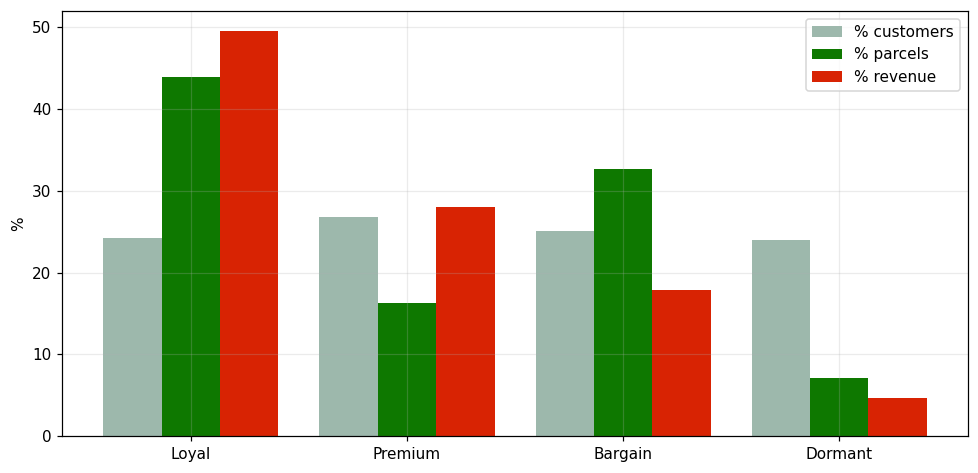

In [11]:
df['cluster'] = labels[4]
p = df.groupby('cluster')[COL].mean()

name = {p.recency.idxmax(): 'Dormant'}                       # longest since last order
rest = [c for c in p.index if c not in name]
name[p.loc[rest].monetary.idxmax()] = 'Premium'              # biggest basket
rest = [c for c in p.index if c not in name]
name[p.loc[rest].discount_rate.idxmax()] = 'Bargain'         # most coupon-driven
name[[c for c in p.index if c not in name][0]] = 'Loyal'     # what is left

df['segment'] = df.cluster.map(name)
ORDER = ['Loyal', 'Premium', 'Bargain', 'Dormant']

profile = df.groupby('segment')[COL].mean().loc[ORDER].round(2)
profile['n'] = df.groupby('segment').size().loc[ORDER]
print(profile.to_string())


g = df.groupby('segment')
revenue = g.apply(lambda d: (d.frequency * d.monetary).sum(), include_groups=False)

hinge = pd.DataFrame({
    'customers': g.size() / len(df),
    'parcels':   g.frequency.sum() / df.frequency.sum(),
    'revenue':   revenue / revenue.sum(),
}).loc[ORDER]
hinge['eur_per_parcel'] = (revenue / g.frequency.sum()).loc[ORDER]

print((hinge[['customers', 'parcels', 'revenue']] * 100).round(1).to_string())
print()
print(hinge[['eur_per_parcel']].round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(4); w = .27
ax.bar(x - w, hinge.customers*100, w, label='% customers', color='#9DB8AC')
ax.bar(x,     hinge.parcels*100,   w, label='% parcels',   color=GREEN)
ax.bar(x + w, hinge.revenue*100,   w, label='% revenue',   color=ACC)
ax.set_xticks(x); ax.set_xticklabels(ORDER); ax.set_ylabel('%')
ax.legend()
plt.tight_layout()
plt.show()



Two sentences join the two halves of this lab:

1. **A quarter of the customers generates 44% of the parcels.** Another
   quarter generates 7%.
2. **Bargain eats 32.7% of the delivery capacity and returns 17.9% of the
   revenue.** Premium does the opposite: 16.3% of the capacity, 28.0% of the
   revenue — 90 EUR per parcel against 29.


| segment | signature | marketing action |
|---|---|---|
| Loyal | orders often, good basket, rarely uses coupons | referral programme — do *not* discount |
| Premium | orders rarely, very large basket | curated assortment, guaranteed delivery windows |
| Bargain | orders often, small basket, 63% on coupon | cap coupon depth: margin risk |
| Dormant | has not ordered in ~8 weeks | win-back campaign, or let them go |

> $k$ is a **business decision** too: 4 segments is 4 campaigns to design,
> staff, budget and monitor.

---
# Part 2 — Where do we ship from?

Corvia already operates four micro-hubs. They are where they are (converted
retail space) and each handles only so many parcels a month. Nothing is being
opened or closed. The only decision left is **who serves whom**.

Still clustering — partition the customers into 4 groups — but now the
cluster centres are **fixed** and each cluster has a **capacity**. No k-means
variant can express the second condition.

In [12]:
df = df.sample(500, random_state=0).copy()  

# scale to 100 X 100 grid

G = df[['x', 'y']].to_numpy()        # customer coordinates
q = df.frequency.to_numpy()          # demand = parcels per month

HUBS = np.array([[4.0, 4.0],         # Porto    — converted shop, small
                 [13.0, 6.0],        # Est      — purpose built, large
                 [8.0, 14.0],        # Nord     — medium
                 [10.0, 10.0]])      # Centrale — medium, central
CAP = np.array([800, 650, 700, 1000], float)
NAME = ['Porto', 'Est', 'Nord', 'Centrale']

D = cdist(G, HUBS)
n, J = D.shape

print(f"customers      {n}")
print(f"total demand   {q.sum():,.0f} parcels/month")
print(f"total capacity {CAP.sum():,.0f}  -> slack {CAP.sum()/q.sum()-1:.1%}")

customers      500
total demand   3,068 parcels/month
total capacity 3,150  -> slack 2.7%


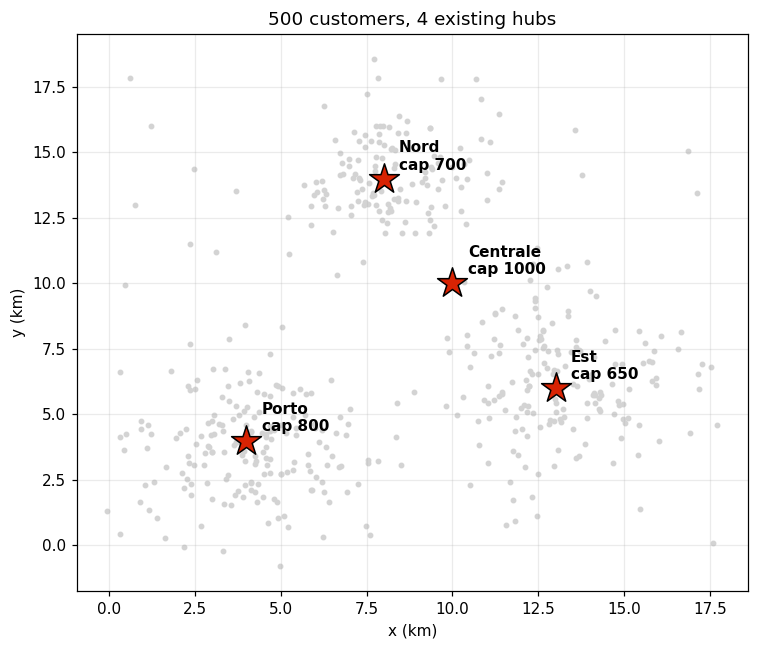

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(G[:, 0], G[:, 1], s=8, c='lightgrey')
plt.scatter(HUBS[:, 0], HUBS[:, 1], marker='*', s=420, c=ACC, edgecolor='k', zorder=3)
for j, nm in enumerate(NAME):
    plt.annotate(f"{nm}\ncap {CAP[j]:.0f}", HUBS[j], textcoords="offset points",
                 xytext=(10, 6), fontweight='bold')
plt.xlabel('x (km)'); plt.ylabel('y (km)')
plt.title(f'{n} customers, 4 existing hubs')
plt.tight_layout()
plt.show()

## 2.1 The obvious answer is not an answer

In [14]:
def cost_of(a, Dm=None):
    Dm = D if Dm is None else Dm
    return (q * Dm[np.arange(n), a]).sum()

def loads_of(a):
    return np.array([q[a == j].sum() for j in range(J)])

a_near = D.argmin(axis=1)

res = pd.DataFrame({'hub': NAME, 'capacity': CAP, 'load': loads_of(a_near).round(0)})
res['utilisation'] = (res.load / res.capacity).map('{:.0%}'.format)
res['overload'] = (res.load - res.capacity).clip(lower=0).round(0)
print(res.to_string(index=False))
print(f"\ncost = {cost_of(a_near):,.0f} parcel-km - but 3 hubs out of 4 are over capacity")

     hub  capacity   load utilisation  overload
   Porto     800.0 1100.0        138%     300.0
     Est     650.0  966.0        149%     316.0
    Nord     700.0  790.0        113%      90.0
Centrale    1000.0  212.0         21%       0.0

cost = 6,985 parcel-km - but 3 hubs out of 4 are over capacity


## 2.2 Model 1 — integer programming

**Data.** $q_i$ demand, $d_{ij}$ distance, $Q_j$ capacity.
**Variable.** $x_{ij} = 1$ if customer $i$ is served by hub $j$.

$$\min \sum_i \sum_j q_i\, d_{ij}\, x_{ij}$$
$$\sum_j x_{ij} = 1 \quad \forall i \qquad\qquad \sum_i q_i\, x_{ij} \le Q_j \quad \forall j$$
$$x_{ij} \in \{0,1\}$$

Note there are **no $y_j$ variables**: nothing is opened or closed, so there
is no activation decision and no fixed cost. This is the **Generalised
Assignment Problem**.

The function below carries two optional arguments we will need for the
exercises — leave them at their defaults for now.

In [15]:
import gurobipy as gp
from gurobipy import GRB


def solve_assignment(Dm=None, cap=None, value=None, max_dist=None, verbose=False):
    """Assign every customer to exactly one hub, respecting capacity.

    Dm       : distance matrix (default: D)
    cap      : hub capacities  (default: CAP)
    value    : per-customer weight v_i in the objective (default: all ones)
    max_dist : per-customer maximum distance to its hub (default: none)
    """
    Dm = D if Dm is None else Dm
    cap = CAP if cap is None else cap
    v = np.ones(n) if value is None else value

    m = gp.Model('capacitated_assignment')
    m.Params.OutputFlag = 1 if verbose else 0

    x = m.addVars(n, J, vtype=GRB.BINARY, name='x')

    m.setObjective(gp.quicksum(v[i] * q[i] * Dm[i, j] * x[i, j]
                               for i in range(n) for j in range(J)), GRB.MINIMIZE)
    m.addConstrs((x.sum(i, '*') == 1 for i in range(n)), name='assign')
    m.addConstrs((gp.quicksum(q[i] * x[i, j] for i in range(n)) <= cap[j]
                  for j in range(J)), name='capacity')

    if max_dist is not None:                      # service-level rule
        for i in range(n):
            for j in range(J):
                if Dm[i, j] > max_dist[i]:
                    x[i, j].UB = 0

    m.optimize()
    if m.Status != GRB.OPTIMAL:
        print(f"  !! not solved to optimality (status {m.Status}; 3 = infeasible)")
        return None, m
    a = np.array([max(range(J), key=lambda j: x[i, j].X) for i in range(n)])
    return a, m


a_ip, m_ip = solve_assignment()
print(f"cost = {m_ip.ObjVal:,.0f} parcel-km   MIP gap {m_ip.MIPGap:.2e}")
print(f"loads {loads_of(a_ip).round(0)}   capacity {CAP}")
print(f"\nprice of capacity: {cost_of(a_ip)/cost_of(a_near)-1:+.1%} "
      f"vs the infeasible nearest-hub solution")
print(f"customers moved away from their nearest hub: "
      f"{(a_ip != a_near).sum()} of {n} ({(a_ip != a_near).mean():.1%})")

Set parameter Username
Set parameter LicenseID to value 2861818
Academic license - for non-commercial use only - expires 2027-09-09
cost = 8,722 parcel-km   MIP gap 3.67e-05
loads [800. 650. 700. 918.]   capacity [ 800.  650.  700. 1000.]

price of capacity: +24.9% vs the infeasible nearest-hub solution
customers moved away from their nearest hub: 112 of 500 (22.4%)


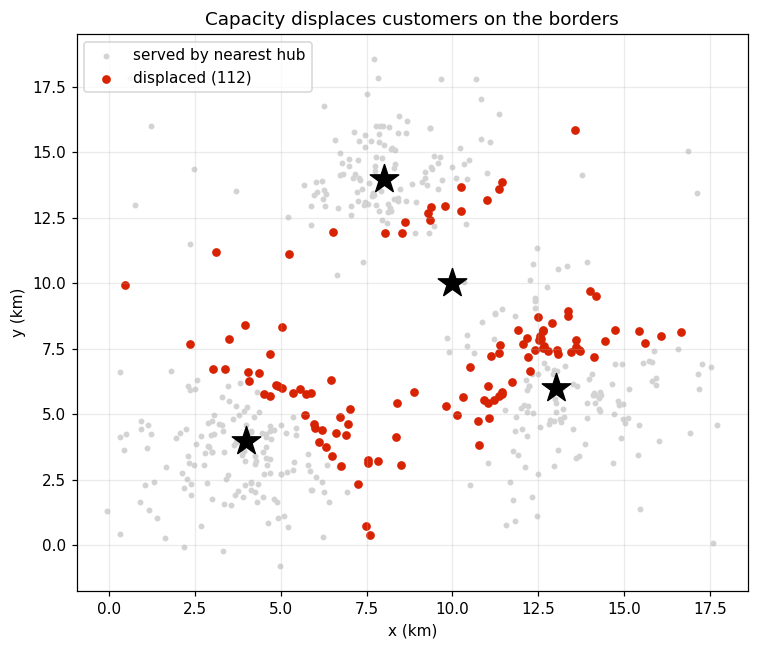

In [16]:
moved = a_ip != a_near
plt.figure(figsize=(7, 6))
plt.scatter(G[~moved, 0], G[~moved, 1], s=8, c='lightgrey', label='served by nearest hub')
plt.scatter(G[moved, 0], G[moved, 1], s=22, c=ACC, label=f'displaced ({moved.sum()})')
plt.scatter(HUBS[:, 0], HUBS[:, 1], marker='*', s=380, c='k', zorder=3)
plt.legend(loc='upper left')
plt.xlabel('x (km)'); plt.ylabel('y (km)')
plt.title('Capacity displaces customers on the borders')
plt.tight_layout()
plt.show()

## 2.3 Model 2 — greedy assignment

Walk through the customers in some order; give each one its nearest hub that
still has room. This is exactly the **assignment step of a capacitated
k-means**, with the centres held fixed.

In [17]:
def greedy(order, Dm=None, cap=None):
    Dm = D if Dm is None else Dm
    rem = (CAP if cap is None else cap).copy()
    a = np.full(n, -1)
    for i in order:
        for j in np.argsort(Dm[i]):          # hubs from nearest to farthest
            if rem[j] >= q[i]:
                a[i] = j
                rem[j] -= q[i]
                break
    return a


a_greedy = greedy(np.arange(n))
print(f"greedy cost = {cost_of(a_greedy):,.0f} parcel-km")
print(f"gap vs the IP optimum: {cost_of(a_greedy)/m_ip.ObjVal-1:+.2%}")

greedy cost = 10,302 parcel-km
gap vs the IP optimum: +18.12%


Feasible, instantaneous — and 18% more expensive than the optimum. The reason
is the **order**: customers processed late find the nearby hubs already full,
and being processed late has nothing to do with how much displacing them costs.

So order them by how much they stand to lose. The **regret** of customer $i$
is what its second-best hub costs it:

$$r_i = q_i\left(d_{i,(2)} - d_{i,(1)}\right)$$

High regret = no good alternative = serve it early.

In [18]:
Dsort = np.sort(D, axis=1)
regret = q * (Dsort[:, 1] - Dsort[:, 0])

orders = {
    'dataset order':     np.arange(n),
    'demand descending': np.argsort(-q),
    'regret descending': np.argsort(-regret),
}

rows = []
for label, o in orders.items():
    a = greedy(o)
    rows.append(dict(rule=label, cost=round(cost_of(a)),
                     gap=f"{cost_of(a)/m_ip.ObjVal-1:+.2%}",
                     unassigned=(a < 0).sum()))
rows.append(dict(rule='IP optimum', cost=round(m_ip.ObjVal), gap='+0.00%', unassigned=0))
print(pd.DataFrame(rows).to_string(index=False))

             rule  cost     gap  unassigned
    dataset order 10302 +18.12%           0
demand descending 10417 +19.44%           0
regret descending  9455  +8.41%           0
       IP optimum  8722  +0.00%           0


**The ordering rule matters more than the algorithm.** Same greedy, same
data: sorting by regret cuts the gap from 18% to 8%, at zero extra
computational cost.

That is the practical lesson about heuristics. The expensive part is rarely
the search; it is knowing *what to decide first*.

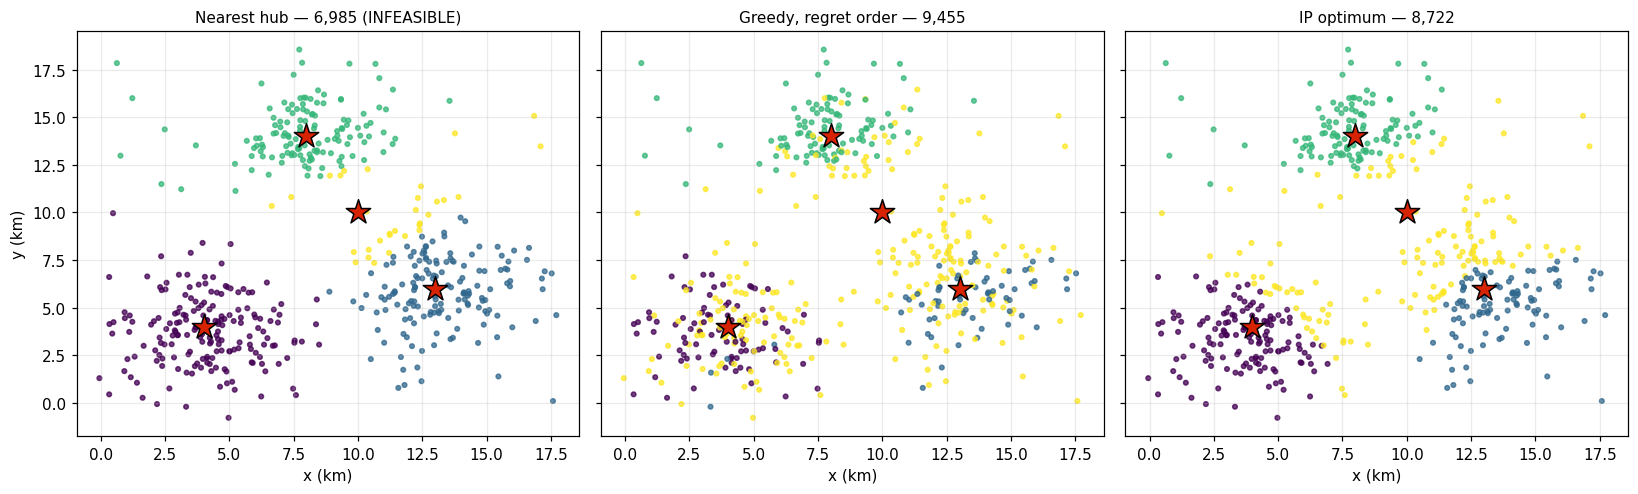

In [19]:
a_regret = greedy(orders['regret descending'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (a, t) in zip(axes, [
        (a_near,   f'Nearest hub — {cost_of(a_near):,.0f} (INFEASIBLE)'),
        (a_regret, f'Greedy, regret order — {cost_of(a_regret):,.0f}'),
        (a_ip,     f'IP optimum — {m_ip.ObjVal:,.0f}')]):
    ax.scatter(G[:, 0], G[:, 1], c=a, cmap='viridis', s=9, alpha=.75)
    ax.scatter(HUBS[:, 0], HUBS[:, 1], marker='*', s=280, c=ACC, edgecolor='k', zorder=3)
    ax.set_title(t, fontsize=10)
    ax.set_xlabel('x (km)')
axes[0].set_ylabel('y (km)')
plt.tight_layout()
plt.show()

Look at the **shape**, not only the cost. The IP territories have clean
borders; the greedy ones are speckled with customers stranded inside someone
else's district — which is a routing problem tomorrow morning.

Impose a per-segment radius — Premium 6 km, Loyal 10 km, Bargain and Dormant
12 km — using the `max_dist` argument of `solve_assignment`, and re-solve.

**What does the promise cost? And what happens first?**

Report the new cost, the mean distance of Premium customers, and how many
customers change hub.

In [20]:
RADIUS = {'Premium': 8, 'Loyal': 10, 'Bargain': 12, 'Dormant': 12}
ub = df.segment.map(RADIUS).to_numpy(float)

a_ip, m_ip = solve_assignment(max_dist=ub)

print(f"cost = {m_ip.ObjVal:,.0f} parcel-km   MIP gap {m_ip.MIPGap:.2e}")
print(f"loads {loads_of(a_ip).round(0)}   capacity {CAP}")
print(f"\nprice of capacity: {cost_of(a_ip)/cost_of(a_near)-1:+.1%} "
      f"vs the infeasible nearest-hub solution")
print(f"customers moved away from their nearest hub: "
      f"{(a_ip != a_near).sum()} of {n} ({(a_ip != a_near).mean():.1%})")

unreachable = (D > ub[:, None]).all(axis=1)
print(f"customers with NO hub inside their radius: {unreachable.sum()}")
print(f"their segments: {df.segment[unreachable].value_counts().to_dict()}")
print(f"distance to their nearest hub: {np.sort(D.min(axis=1)[unreachable]).round(1)}")

cost = 8,725 parcel-km   MIP gap 9.90e-05
loads [800. 650. 700. 919.]   capacity [ 800.  650.  700. 1000.]

price of capacity: +24.9% vs the infeasible nearest-hub solution
customers moved away from their nearest hub: 111 of 500 (22.2%)
customers with NO hub inside their radius: 0
their segments: {}
distance to their nearest hub: []


## 2.5 And if the hubs could move? (capacitated k-means)

The greedy above is the *assignment* step of k-means. Add the *update* step —
move each hub to the (demand-weighted) centre of the customers it serves —
and iterate. That answers a different managerial question: **where should the
hubs have been?**

We now have two assignment rules (greedy and exact) and two location regimes
(fixed and free). Let us fill in all four cells: mixing them up is the classic
way to credit a capital project for a gain that came from software.

In [21]:
def assign_greedy(Dm):
    rg = q * (np.sort(Dm, axis=1)[:, 1] - np.sort(Dm, axis=1)[:, 0])
    a = greedy(np.argsort(-rg), Dm=Dm)
    return a, cost_of(a, Dm)


def assign_exact(Dm):
    a, mm = solve_assignment(Dm=Dm)
    return a, mm.ObjVal


def capacitated_kmeans(assign, n_iter=25):
    """k-means, but the assignment step must respect hub capacities.

    Note we keep the BEST iterate, not the last one: once the assignment step
    is constrained, k-means loses its guarantee that every iteration improves.
    """
    C, hist, best = HUBS.copy(), [], None
    for _ in range(n_iter):
        a, c = assign(cdist(G, C))
        hist.append(c)
        if best is None or c < best[0]:
            best = (c, C.copy(), a.copy())
        # update step: each hub moves to the demand-weighted centre of its customers
        C_new = np.array([np.average(G[a == j], axis=0, weights=q[a == j])
                          if (a == j).any() else C[j] for j in range(J)])
        if np.allclose(C_new, C, atol=1e-5):
            break
        C = C_new
    return best, hist


(c_g, _, _), hist_g = capacitated_kmeans(assign_greedy)
(c_i, C_best, a_ck), hist_i = capacitated_kmeans(assign_exact)

grid = pd.DataFrame([[hist_g[0], hist_i[0]], [c_g, c_i]],
                    index=['hubs fixed', 'hubs relocated'],
                    columns=['greedy assignment', 'exact assignment (IP)']).round(0)
print(grid.to_string())
print(f"\nbetter ASSIGNMENT, same buildings : {hist_i[0]/hist_g[0]-1:+.1%}")
print(f"better LOCATIONS,  same solver     : {c_i/hist_i[0]-1:+.1%}")

                greedy assignment  exact assignment (IP)
hubs fixed                 9455.0                 8722.0
hubs relocated             8518.0                 7969.0

better ASSIGNMENT, same buildings : -7.8%
better LOCATIONS,  same solver     : -8.6%


**Read that table across, then down.** On this instance the two levers are
worth about the same: roughly 8% from assigning better (a change of
software) and roughly 8% more from moving the buildings (a change of real
estate) — and the second is the one that takes two years and a budget.

That is the habit worth keeping: before costing a capital project, measure
how much of the gain is simply better use of what already exists. Here it is
half of it, free.

Note how sensitive this split is. With four hubs sitting exactly on their
districts and comfortable capacity, the assignment lever dominates and
relocation is nearly worthless. Squeeze capacity to 3% slack, as we did, and
the badly-placed hub starts to cost real money. The conclusion is a property
of *this* network, not a law.

suggested relocation:
  Porto     (  4.0,  4.0) -> (  3.3,  3.6)   0.8 km
  Est       ( 13.0,  6.0) -> ( 14.0,  5.4)   1.2 km
  Nord      (  8.0, 14.0) -> (  8.0, 14.5)   0.5 km
  Centrale  ( 10.0, 10.0) -> (  9.5,  7.5)   2.6 km


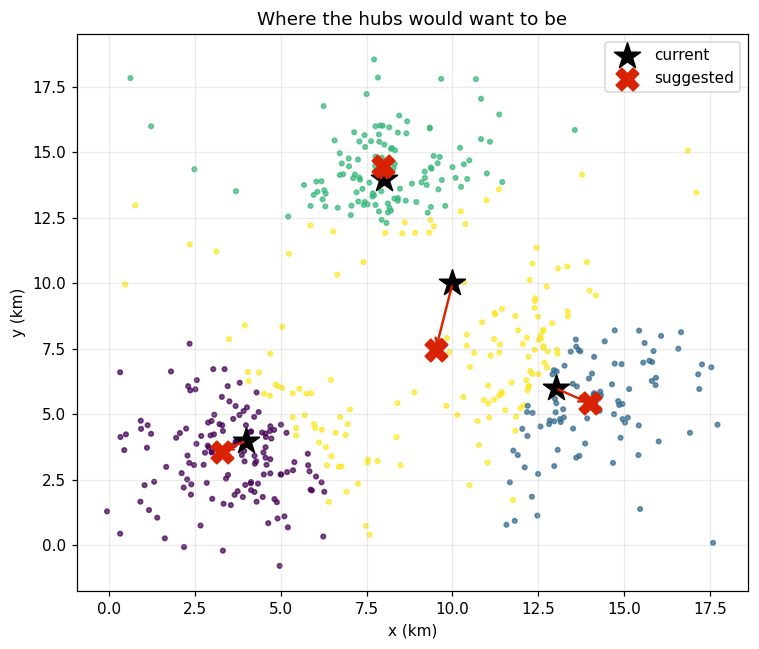

In [22]:
print("suggested relocation:")
for j, nm in enumerate(NAME):
    print(f"  {nm:9s} ({HUBS[j,0]:5.1f},{HUBS[j,1]:5.1f}) -> "
          f"({C_best[j,0]:5.1f},{C_best[j,1]:5.1f})   "
          f"{np.linalg.norm(C_best[j]-HUBS[j]):.1f} km")

plt.figure(figsize=(7, 6))
plt.scatter(G[:, 0], G[:, 1], c=a_ck, cmap='viridis', s=9, alpha=.7)
plt.scatter(HUBS[:, 0], HUBS[:, 1], marker='*', s=320, c='k', label='current', zorder=3)
plt.scatter(C_best[:, 0], C_best[:, 1], marker='X', s=220, c=ACC, label='suggested', zorder=3)
for j in range(J):
    plt.annotate('', C_best[j], HUBS[j], arrowprops=dict(arrowstyle='->', color=ACC, lw=1.6))
plt.legend()
plt.xlabel('x (km)'); plt.ylabel('y (km)')
plt.title('Where the hubs would want to be')
plt.tight_layout()
plt.show()

Three hubs barely move — they already sit on their districts. Only *Centrale*
is genuinely misplaced, drifting west to cover the overflow it absorbs. A
relocation study with a one-line conclusion is the best kind.

Two caveats before anyone quotes the saving. The loop is a heuristic
converging to a local optimum, so the number is a **lower bound** on what
relocation could achieve. And it ignores the cost of relocating, which is
exactly what the study would have to justify.



> Open 4 micro-hubs among 10 candidate sites. Every customer is served by
> exactly one hub. Each hub can handle at most `CAP` orders per month.
> Minimise total travel distance.

k-means cannot express "at most CAP orders". An IP can.

**Sets** — customers $I$, candidate sites $J$.
**Data** — $d_{ij}$ distance, $q_i$ demand (orders/month), $Q$ hub capacity, $p$ hubs to open.

**Variables**
$$y_j \in \{0,1\}\ \text{hub } j \text{ open}, \qquad x_{ij} \in \{0,1\}\ \text{customer } i \to \text{hub } j$$

**Model**
$$\min \sum_{i \in I}\sum_{j \in J} q_i\, d_{ij}\, x_{ij}$$
$$\sum_{j \in J} x_{ij} = 1 \quad \forall i \in I \qquad \text{(each customer assigned once)}$$
$$\sum_{i \in I} q_i\, x_{ij} \le Q\, y_j \quad \forall j \in J \qquad \text{(capacity + linking)}$$
$$\sum_{j \in J} y_j = p \qquad \text{(open exactly p hubs)}$$

Note how the capacity constraint doubles as the linking constraint:
if $y_j = 0$ the right-hand side is 0, so no customer can be assigned to $j$.

In [23]:
import gurobipy as gp
from gurobipy import GRB
RNG = np.random.default_rng(42)

n_sites, p = 10, 4
sites = np.column_stack([RNG.uniform(1, 17, n_sites), RNG.uniform(1, 17, n_sites)])
q = df["frequency"].to_numpy()                 # monthly demand proxy
d = cdist(G, sites)                              # euclidean distance matrix (km)

# capacity: the p open sites must absorb total demand, with 2% slack
CAP_SITE = int(np.ceil(q.sum() / p * 1.02))   # NB: a separate name, so CAP (the
                                              # four existing hubs) stays intact
print(f"customers={len(q)}  total demand={q.sum():.0f}  site capacity={CAP_SITE}")

def solve_hub_model(cap, p, forbid_beyond_km=None, verbose=False):
    """Return (objective, assignment, opened, loads) for the p-hub model."""
    m = gp.Model("hub_clustering")
    m.Params.OutputFlag = 1 if verbose else 0
    n, J = len(q), n_sites

    x = m.addVars(n, J, vtype=GRB.BINARY, name="x")
    y = m.addVars(J, vtype=GRB.BINARY, name="y")

    m.setObjective(gp.quicksum(q[i] * d[i, j] * x[i, j]
                               for i in range(n) for j in range(J)), GRB.MINIMIZE)
    m.addConstrs((x.sum(i, "*") == 1 for i in range(n)), name="assign")
    m.addConstrs((gp.quicksum(q[i] * x[i, j] for i in range(n)) <= cap * y[j]
                  for j in range(J)), name="cap")
    m.addConstr(y.sum() == p, name="p_hubs")

    if forbid_beyond_km is not None:                    # service-level rule
        for i in range(n):
            for j in range(J):
                if d[i, j] > forbid_beyond_km:
                    x[i, j].UB = 0

    m.optimize()
    if m.Status != GRB.OPTIMAL:
        print(f"  !! status {m.Status} (3 = infeasible)")
        return None
    opened = [j for j in range(J) if y[j].X > .5]
    assign = np.array([next(j for j in range(J) if x[i, j].X > .5) for i in range(n)])
    loads = np.array([q[assign == j].sum() for j in range(J)])
    return m.ObjVal, assign, opened, loads


# (a) capacity switched OFF -> this is the classic p-median problem
BIG = q.sum()
obj_pm, assign_pm, opened_pm, load_pm = solve_hub_model(BIG, p)

# (b) capacity switched ON
obj_ip, assign_ip, opened_ip, load_ip = solve_hub_model(CAP_SITE, p)

print(f"p-median (no capacity) : {obj_pm:>9,.0f} order-km | "
      f"loads {np.sort(load_pm[opened_pm])[::-1].astype(int)} | "
      f"max overload {max(0, load_pm[opened_pm].max() - CAP_SITE):.0f}")
print(f"capacitated            : {obj_ip:>9,.0f} order-km | "
      f"loads {np.sort(load_ip[opened_ip])[::-1].astype(int)} | "
      f"max overload {max(0, load_ip[opened_ip].max() - CAP_SITE):.0f}")
print(f"\nPrice of capacity: {(obj_ip - obj_pm) / obj_pm:+.1%} extra distance")

customers=500  total demand=3068  site capacity=783
p-median (no capacity) :     9,930 order-km | loads [1047  959  789  271] | max overload 264
capacitated            :    10,742 order-km | loads [782 782 782 720] | max overload 0

Price of capacity: +8.2% extra distance


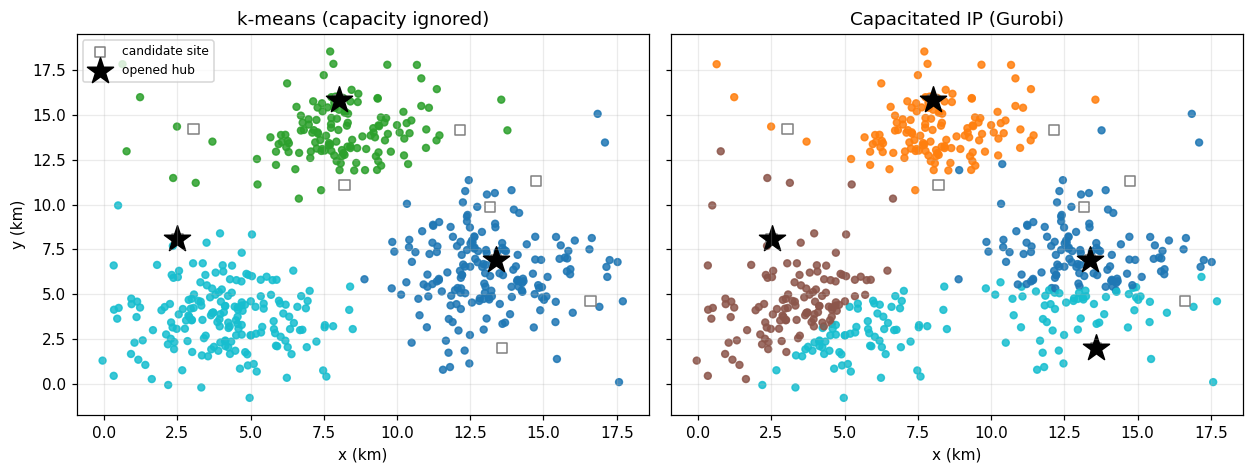

In [24]:

km4 = KMeans(n_clusters=4, n_init=20, random_state=0).fit(G)
snap = [int(np.argmin(np.linalg.norm(sites - c, axis=1))) for c in km4.cluster_centers_]
assign_km = np.array([snap[l] for l in km4.labels_])
cost_km = sum(q[i] * d[i, assign_km[i]] for i in range(len(q)))
load_km = np.array([q[assign_km == j].sum() for j in range(n_sites)])


fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True, sharey=True)
for a, (lab, title, op) in zip(
        ax,
        [(assign_km, "k-means (capacity ignored)", set(snap)),
         (assign_ip, "Capacitated IP (Gurobi)", opened_ip)]):
    a.scatter(G[:, 0], G[:, 1], c=lab, cmap="tab10", s=20, alpha=.85)
    a.scatter(sites[:, 0], sites[:, 1], marker="s", s=45,
              facecolor="none", edgecolor="grey", label="candidate site")
    a.scatter(sites[list(op), 0], sites[list(op), 1], marker="*", s=320,
              c="black", label="opened hub")
    a.set_title(title); a.set_xlabel("x (km)")
ax[0].set_ylabel("y (km)"); ax[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()